# Week 3 · kNN from the smallest piece, and a NumPy shape workout

Your log on Oct 25: *"i couldnt build kNN at all"* and *"i am having more trouble with numpy than the ML concept itself."* So this notebook builds kNN **one line at a time**. Each line gets a picture of what NumPy does, one case worked by hand, and a tiny exercise with a checker. Section 8 is a workout built on your own question from Week 2: **one per sample, one per feature, or one number?** Every exercise says the shape to expect. Write that shape down before you write the code.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **query**: The new point you want a prediction for. Written $q$, shape `(d,)`.
- **`np.argsort`**: Returns the **positions** that would sort an array, smallest first. Not the sorted values.
- **fancy indexing**: Indexing with an array of positions: `y[[2, 3, 4]]` picks entries 2, 3 and 4.
- **`np.bincount`**: Counts how many times each whole number 0, 1, 2, ... appears. `np.bincount([1, 0, 1])` is `[1, 2]`.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "02")      # defines check(n)

## 0. Recap first · 10 min, closed book

**Quick check:** In logistic regression, one point has label 1 and $\hat p = 0.2$. Which way does it pull $w$, and how hard?

<details><summary>Answer</summary>

Its pull is $\hat p - y = -0.8$, so the step adds $0.8\,\eta\, x$ to $w$: $w$ turns **toward** that point, hard. [01 §6 ↗](01_logistic_regression_in_pictures.ipynb)

</details>

**Quick check:** You lower the threshold from 0.5 to 0.25. Which way does the decision line move, and what happens to recall?

<details><summary>Answer</summary>

It slides parallel, toward the class-0 side, to the line $z = \ln\frac{0.25}{0.75} = -1.1$. More points are predicted 1, so recall goes up (or stays the same). [01 §9 ↗](01_logistic_regression_in_pictures.ipynb)

</details>

**Quick check:** What is average precision (PR-AUC), in words?

<details><summary>Answer</summary>

The average of the precisions at the moments you catch each real positive, going down the ranked list. Random guessing gives about the fraction of positives. [01 §10 ↗](01_logistic_regression_in_pictures.ipynb)

</details>

**Quick check:** Shape of `np.ones((4, 1)) + np.ones(3)`?

<details><summary>Answer</summary>

`(4, 3)`. Line the shapes up from the right: 1 vs 3, so the 1 stretches; then 4 vs nothing is fine. [Week 2 · 03 §2, rule 3 ↗](../week2/03_shapes_and_slicing.ipynb)

</details>

In [3]:
print(np.ones((4,1)))
print(np.ones(3))
print(np.ones((4,1)) + np.ones(3))

[[1.]
 [1.]
 [1.]
 [1.]]
[1. 1. 1.]
[[2. 2. 2.]
 [2. 2. 2.]
 [2. 2. 2.]
 [2. 2. 2.]]


**Quick check:** Write ridge regression's closed-form solution.

<details><summary>Answer</summary>

$\hat w = (X^\top X + \lambda I)^{-1} X^\top y$, computed with `np.linalg.solve(X.T @ X + lam * np.eye(d), X.T @ y)`. [Week 2 · 04 §6 ↗](../week2/04_ml_intro_linear_regression.ipynb)

</details>

## 1. The whole of kNN, with its shapes

**kNN is four lines: distances, the $k$ smallest, their labels, a vote.** Each line has one NumPy idea in it. Here's the whole thing for one query, with the shape after every step:

| Step | Code | Result | Shape | One per... |
|---|---|---|---|---|
| 0. the data | `X_train`, `q` | training points; the query | `(n, d)`, `(d,)` |  |
| 1. distances | distance from `q` to every row | `dist` | `(n,)` | training point |
| 2. the k nearest | `np.argsort(dist)[:k]` | `idx`: their positions | `(k,)` | neighbor |
| 3. their labels | `y_train[idx]` | `labels` | `(k,)` | neighbor |
| 4. the vote | `np.bincount(labels).argmax()` | the prediction | `()` | (one number) |

We use the six points from [Week 2 · 05 §5 ↗](../week2/05_logistic_regression_knn.ipynb) again, now with labels 0 and 1, and the query $q = (3.5, 3)$:

In [4]:
X_train = np.array([[1, 2], [2, 1], [2, 3], [5, 4], [4, 5], [6, 6]], dtype=float)   # (6, 2)
y_train = np.array([0, 0, 0, 1, 1, 1])                                               # (6,)
q = np.array([3.5, 3.0])                                                             # (2,)

🖼 **Picture.** The query (star), its distance to every training point, and the 3 nearest inside the dashed circle.

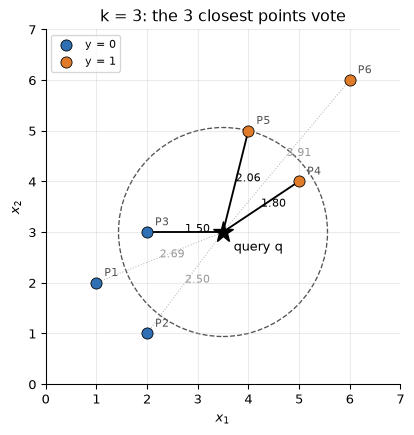

In [5]:
fig_knn_query(q=(3.5, 3.0), k=3)

## 2. Step 1: the distance to every training point

**`X_train - q` subtracts the query from every row at once (broadcasting). Squaring, summing across each row and taking the square root gives one distance per training point.**

$$
d_i = \lVert x_i - q \rVert = \sqrt{\textstyle\sum_{j=1}^{d} (x_{ij} - q_j)^2}
$$

🖼 **Picture.** Step 1 drawn as tables, left to right. Row 0 (yellow) is followed through every step. `q` is used for every row without being copied in memory (grey).

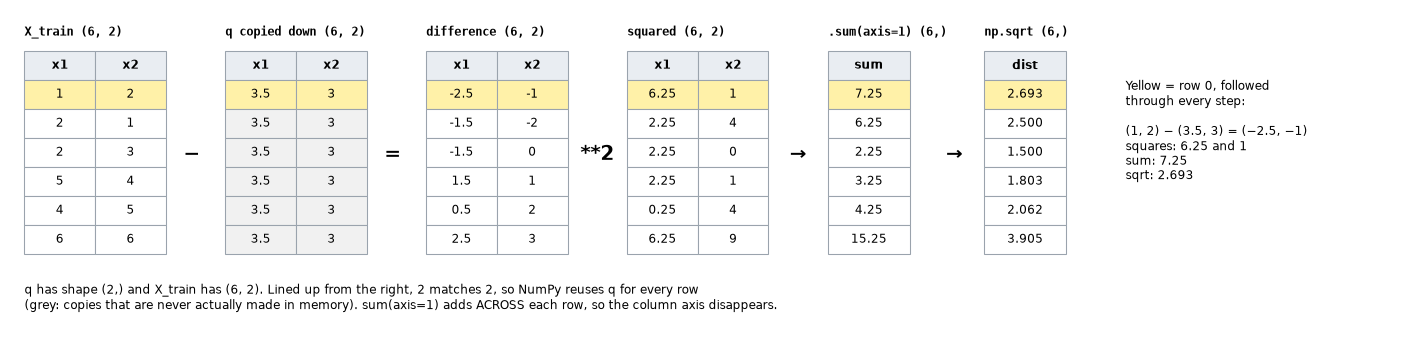

In [6]:
fig_broadcast_distances()

**Row 0 by hand**

- Row 0 is $(1, 2)$. Differences: $1 - 3.5 = -2.5$ and $2 - 3 = -1$.
- Squares: $6.25$ and $1$. Sum: $7.25$.
- $\sqrt{7.25} = 2.693$: the first entry of `dist`.

✏️ **Exercise 1 · Distances.** Return the Euclidean distance from `q` (shape `(d,)`) to every row of `X_train` (shape `(n, d)`). **Shape: `(n,)`**, one per training point. Use broadcasting, `** 2`, `.sum(axis=...)` and `np.sqrt`, with no loop. Which axis do you sum over?

In [1]:
def distances(X_train, q):
    return np.sqrt(((X_train - q)**2).sum(axis =1))

In [8]:
check(1)

Exercise 1: PASS


## 3. Step 2: the positions of the $k$ smallest

**`np.argsort(dist)` lists the positions of the entries from smallest to largest. The first $k$ of them are the $k$ nearest neighbors.**

🖼 **Picture.** Top: `dist`, with each value's position. Bottom: `np.argsort(dist)`, i.e. the **positions**, reordered from the smallest distance to the largest (the distance is in grey underneath). The arrows show where each one came from. Yellow: the first 3.

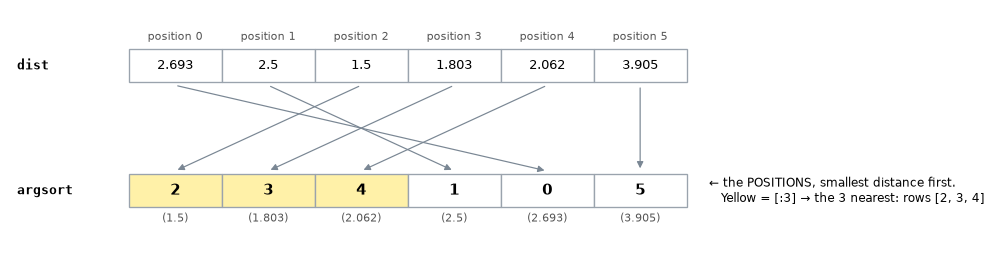

In [9]:
fig_argsort()

It's the same idea as `argmax` in [Week 2 · 02 §1 ↗](../week2/02_map_and_entropy_in_depth.ipynb): **arg** means "give me the position, not the value". The positions are what you need, because the next step uses them to look up labels.

> ⚠️ **Common mistake.** `np.sort(dist)[:3]` gives the three smallest **distances**, `[1.5, 1.803, 2.062]`, which are useless here: you can't tell which points they belong to. You want `np.argsort`.

✏️ **Exercise 2 · The k nearest.** Given `dist` (shape `(n,)`), return the positions of the `k` smallest distances, nearest first. **Shape: `(k,)`.**

In [10]:
def nearest(dist, k):
    return np.argsort(dist)[:k]

In [11]:
check(2)

Exercise 2: PASS


## 4. Step 3: looking up their labels

**Indexing an array with an array of positions picks those entries, in that order.** It's called fancy indexing.

🖼 **Picture.** `y_train[[2, 3, 4]]`: each position in the list picks one entry, in that order. The result has one label per neighbor.

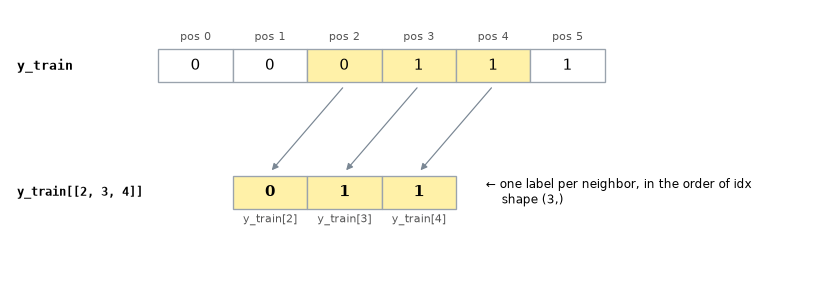

In [12]:
fig_fancy_index()

In [13]:
dist = np.sqrt(((X_train - q) ** 2).sum(axis=1))
idx = np.argsort(dist)[:3]
print(idx, y_train[idx])     # → [2 3 4] [0 1 1]

[2 3 4] [0 1 1]


## 5. Step 4: the vote

**`np.bincount` counts each label, and `argmax` picks the label with the biggest count.**

🖼 **Picture.** `np.bincount([0, 1, 1])` counts how many times each label appears: position 0 holds the count of 0s, position 1 the count of 1s. `argmax` returns the position of the tallest bar, which is the winning label.

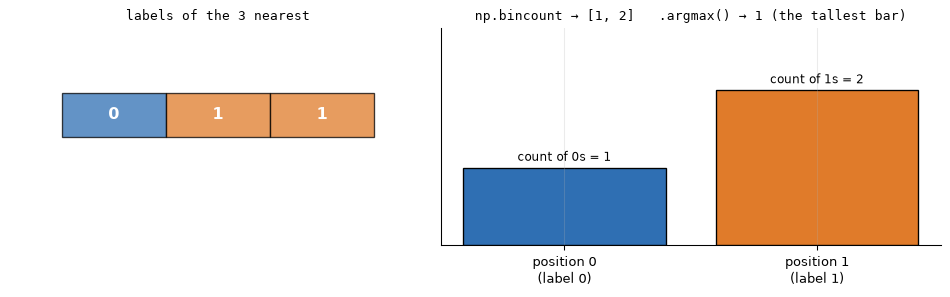

In [14]:
fig_bincount()

- Three classes: `np.bincount([2, 0, 2, 1])` is `[1, 1, 2]` (one 0, one 1, two 2s), so `argmax` is 2.
- A tie: `np.bincount([1, 0])` is `[1, 1]`. `argmax` returns the **first** maximum, so the answer is 0, the smaller label.

`bincount` works because the labels are whole numbers 0, 1, 2, ...: it uses each label as a **position** in the count array. For text labels such as `"A"`/`"B"`, use `collections.Counter(labels).most_common(1)` instead.

✏️ **Exercise 3 · Vote.** Given an array of integer labels (shape `(k,)`), return the most common one as an `int`. When there's a tie, return the smallest label (that's what `argmax` does anyway). **Shape: `()`**, one number.

In [15]:
def vote(labels):
    return np.bincount(labels).argmax()

In [16]:
check(3)

Exercise 3: PASS


## 6. Putting it together

Each step is now one function, so kNN for one query is one line: vote on the labels of the nearest distances. For many queries, loop over the rows of `X_test`.

✏️ **Exercise 4 · kNN for one query.** Use your `distances`, `nearest` and `vote`. Return the predicted label for one query `q`. **Shape: `()`.**

In [17]:
def knn_predict_one(X_train, y_train, q, k):
    dist = ((X_train - q)**2).sum(axis=1)
    idx = np.argsort(dist)[:k]
    return np.bincount(y_train[idx]).argmax()

In [18]:
check(4)

Exercise 4: PASS


✏️ **Exercise 5 · kNN for many queries.** Loop over the rows of `X_test` (shape `(m, d)`), call `knn_predict_one` for each, and return the predictions as a NumPy array. **Shape: `(m,)`.**

In [19]:
def knn_predict(X_train, y_train, X_test, k):
    l = []
    for i in range(X_test.shape[0]):
        l.append(knn_predict_one(X_train,y_train,X_test[i,:],k))
    return np.array(l) 

#def knn_predict(X_train, y_train, X_test, k):
    return np.array([knn_predict_one(X_train, y_train, x, k) for x in X_test])
# above is a much cleaner way to iterate through the rows of X_test and return the answer via list comprehension

In [20]:
check(5)

Exercise 5: PASS


## 7. All queries at once, and what $k$ does

**Add a new axis to each array so that every test point meets every training point. You get a whole table of distances, of shape `(m, n)`, with no loop.**

| Step | Code | Shape | Meaning |
|---|---|---|---|
| test points | `X_test` | `(m, d)` | one row per test point |
| add an axis | `X_test[:, None, :]` | `(m, 1, d)` | one "sheet" per test point |
| add an axis | `X_train[None, :, :]` | `(1, n, d)` | the training set, once |
| subtract | `X_test[:, None, :] - X_train[None, :, :]` | `(m, n, d)` | every test point minus every training point (the 1s stretch) |
| distances | `np.sqrt((diff ** 2).sum(axis=2))` | `(m, n)` | `D[i, j]` = distance from test point `i` to training point `j` |
| k nearest | `np.argsort(D, axis=1)[:, :k]` | `(m, k)` | sort **each row**; keep the first `k` positions |
| their labels | `y_train[idx]` | `(m, k)` | a 2-D index gives a 2-D result |
| vote | `vote(row)` for each row | `(m,)` | one prediction per test point |

**Two queries by hand**

Test points $(3.5, 3)$ and $(1.5, 1.5)$ against the six training points:

|  | train 0 | train 1 | train 2 | train 3 | train 4 | train 5 | 3 nearest | their labels | vote |
|---|---|---|---|---|---|---|---|---|---|
| test 0 $(3.5, 3)$ | 2.693 | 2.500 | 1.500 | 1.803 | 2.062 | 3.905 | 2, 3, 4 | 0, 1, 1 | **1** |
| test 1 $(1.5, 1.5)$ | 0.707 | 0.707 | 1.581 | 4.301 | 4.301 | 6.364 | 0, 1, 2 | 0, 0, 0 | **0** |

In [21]:
X_test = np.array([[3.5, 3.0], [1.5, 1.5]])
diff = X_test[:, None, :] - X_train[None, :, :]
print(diff.shape)                                 # → (2, 6, 2)
D = np.sqrt((diff ** 2).sum(axis=2))
idx = np.argsort(D, axis=1)[:, :3]
print(idx)                                        # → [[2 3 4]
                                                  #    [0 1 2]]
print(y_train[idx])                               # → [[0 1 1]
                                                  #    [0 0 0]]
# i cant clearly grasp what axis to sort for sum over for the kNN to work.

(2, 6, 2)
[[2 3 4]
 [0 1 2]]
[[0 1 1]
 [0 0 0]]


### kNN: which axis to sum, which to sort

**Name the axes first.** `diff = X_test[:, None, :] - X_train[None, :, :]` has shape `(m, n, d)`:

| Axis | Meaning |
|---|---|
| 0 | which **test** point |
| 1 | which **training** point |
| 2 | which **feature** |

`diff[i, j, :]` = test point $i$ minus training point $j$.

**`sum(axis=2)` → features disappear.** A distance combines all features of one pair into one number:
```python
D = np.sqrt((diff ** 2).sum(axis=2))    # (m, n): D[i, j] = distance from test i to train j
```

**`argsort(axis=1)` → rank along training points.** For each test point (each row), sort its distances to all training points:
```python
idx = np.argsort(D, axis=1)[:, :k]      # (m, k): each test point's k nearest training rows
y_train[idx]                            # (m, k): their labels → majority vote per row
```

**Wrong axes would mean:**
- `sum(axis=0)` or `sum(axis=1)` → adds across test points or neighbors, meaningless
- `argsort(axis=0)` → "for each training point, which test point is closest?" (backwards)

**Recipe:** name each axis, then ask
- `sum` / `mean` / `norm`: which axis should **disappear**?
- `argsort` / `argmax`: which axis am I **choosing among**?

✏️ **Exercise 6 · Distance matrix.** Return the `(m, n)` matrix of distances between every row of `A` (shape `(m, d)`) and every row of `B` (shape `(n, d)`), with no loop. **Shape: `(m, n)`.**

In [22]:
def distance_matrix(A, B):
    diff = A[:,None,:] - B[None,:,:]
    return np.sqrt((diff**2).sum(axis=2))

In [23]:
check(6)

Exercise 6: PASS


✏️ **Exercise 7 · kNN, all at once.** Use `distance_matrix(X_test, X_train)`, then `np.argsort(..., axis=1)[:, :k]`, then `y_train[idx]`, then `vote` on each row. **Shape: `(m,)`.** It must give exactly the same answers as exercise 5.

In [24]:
def knn_predict_fast(X_train, y_train, X_test, k):
    diff = X_test[:, None, :] - X_train[None, :, :]          # (m, n, d)
    dist = np.sqrt((diff ** 2).sum(axis=2))                   # (m, n)
    idx = np.argsort(dist, axis=1)[:, :k]                     # (m, k)
    return np.array([np.bincount(row).argmax() for row in y_train[idx]])   # (m,)

# i had trouble writing this :(

In [25]:
check(7)

Exercise 7: PASS


🖼 **Picture.** kNN's decision regions on 200 noisy points. $k = 1$ draws an island around every point (it overfits: training accuracy 1.00). $k = 25$ is smooth but starts to miss the curve.

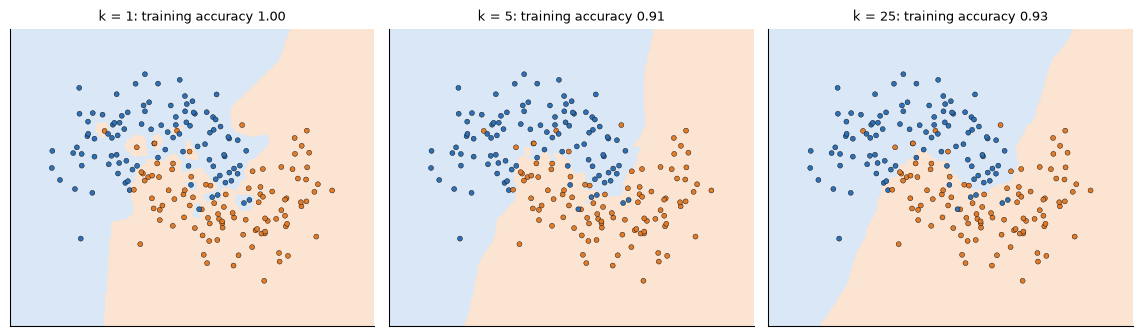

In [26]:
fig_knn_regions(ks=(1, 5, 25))

**kNN for regression:** instead of voting, average the neighbors' $y$ values. That's the only change.

✏️ **Exercise 8 · kNN regression.** Same as exercise 7, but `y_train` holds real numbers. Return the **mean** of the $k$ nearest neighbors' values for each test point. `y_train[idx]` has shape `(m, k)`: which axis do you average over? **Shape: `(m,)`.**

In [27]:
def knn_regress(X_train, y_train, X_test, k):
    diff = X_test[:,None,:] - X_train[None,:,:]
    dist = np.sqrt((diff**2).sum(axis = 2))
    idx = np.argsort(dist, axis = 1)[:,:k]
    return y_train[idx].mean(axis = 1)

# did alot better than exercise 7 after reviewing the mistakes i made.

In [28]:
check(8)

Exercise 8: PASS


## 8. The shape workout: one per sample, one per feature, or one number?

> ↩ **Recap** · [Your own table in Week 2 · 07 (after exercise 12) ↗](../week2/07_exercises.ipynb)
>
> `(n,)` means one per **sample**: `y`, `X @ w`, errors, per-sample losses. `(d,)` means one per **feature**: `w`, the gradient, column means and stds. `()` means **one number**: a loss, $R^2$, accuracy. Collapse only when the result should be one number.

Ten short exercises. For each, **say the shape out loud before writing anything**, then write one line. `X` always has shape `(n, d)`.

| Exercise | Answers the question | Shape |
|---|---|---|
| 9 | the average of each feature | one per feature `(d,)` |
| 10 | every value, standardized | same as `X`: `(n, d)` |
| 11 | the length of each sample | one per sample `(n,)` |
| 12 | one prediction per sample | `(n,)` |
| 13 | mean squared error | one number `()` |
| 14 | the gradient of the MSE | `(d,)` |
| 15 | one-hot labels | `(n, k)` |
| 16 | a softmax for each row | `(n, k)` |
| 17 | the mean of each class | `(k, d)` |
| 18 | accuracy | `()` |

✏️ **Exercise 9 · Feature means.** The mean of each column of `X`. **Shape `(d,)`.** Which `axis`?

In [29]:
def feature_means(X):
    return X.mean(axis=0)

In [30]:
check(9)

Exercise 9: PASS


✏️ **Exercise 10 · Standardize.** Subtract each column's mean and divide by each column's standard deviation (`X.std(axis=...)`). **Shape `(n, d)`.** Broadcasting does the rest.

In [31]:
def standardize(X):
    return (X - X.mean(axis=0))/X.std(axis=0)

In [32]:
check(10)

Exercise 10: PASS


✏️ **Exercise 11 · Row norms.** The length $\lVert x_i \rVert$ of each row, without `np.linalg.norm`. **Shape `(n,)`.**

In [33]:
def row_norms(X):
    return np.linalg.norm(X, axis=1)

In [34]:
check(11)

Exercise 11: PASS


✏️ **Exercise 12 · Linear predictions.** $\hat y = Xw + b$ with `w` of shape `(d,)` and a number `b`. **Shape `(n,)`.**

In [35]:
def predict_linear(X, w, b):
    return X@w +b

In [36]:
check(12)

Exercise 12: PASS


✏️ **Exercise 13 · Mean squared error.** $\frac{1}{n} \sum_i (y_i - \hat y_i)^2$. **Shape `()`**: this is where collapsing to one number is right.

In [37]:
def mse(y, y_hat):
    return np.mean((y-y_hat)**2)

In [38]:
check(13)

Exercise 13: PASS


✏️ **Exercise 14 · MSE gradient.** $\frac{2}{n} X^\top (Xw - y)$. **Shape `(d,)`**: one per weight. No `np.mean` here (that was your Week 2 bug).

In [39]:
def mse_gradient(X, y, w):
    return 2*X.T@(X@w - y)/len(y)

In [40]:
check(14)

Exercise 14: PASS


✏️ **Exercise 15 · One-hot.** Labels `y` of shape `(n,)` with values $0, \dots, k - 1$ become a `(n, k)` matrix with a single 1 in each row, at column `y[i]`. Hint: `np.eye(k)` is a `(k, k)` matrix whose row `c` is the one-hot vector for class `c`; fancy indexing does the rest.

In [41]:
def one_hot(y, k):
    return np.eye(k)[y]

In [42]:
check(15)

Exercise 15: PASS


✏️ **Exercise 16 · Softmax per row.** Each row of `Z` (shape `(n, k)`) becomes probabilities: $\frac{e^{z_j}}{\sum_l e^{z_l}}$. Subtract each row's max first (`keepdims=True`) so that `[[1000, 1001]]` doesn't overflow. **Shape `(n, k)`**, and every row sums to 1.

In [43]:
def softmax_rows(Z):
    Z_new = np.exp(Z - np.max(Z, axis = 1, keepdims=True))
    return Z_new/Z_new.sum(axis = 1, keepdims=True)


In [44]:
check(16)

Exercise 16: PASS


✏️ **Exercise 17 · Class means.** For each class $c = 0, \dots, k - 1$, the mean of the rows of `X` with `y == c`. **Shape `(k, d)`.** A mask, `X[y == c]`, keeps whole rows. (LDA in Week 4 uses this.)

In [45]:
def class_means(X, y, k):
    l = []
    for i in range(k):
        l.append(np.mean(X[y==i], axis = 0))
    return np.array(l)

# didnt know there was a thing like X[y==c]. interesting.

In [46]:
check(17)

Exercise 17: PASS


✏️ **Exercise 18 · Accuracy.** The fraction of positions where `y == y_hat`. **Shape `()`.** One line: `y == y_hat` is a True/False array, and the mean of True/False is the fraction of Trues.

In [47]:
def accuracy(y, y_hat):
    return np.mean(y == y_hat)

In [48]:
check(18)

Exercise 18: PASS


In [49]:
for n in range(1, 19):     # run every check at once
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS
Exercise 5: PASS
Exercise 6: PASS
Exercise 7: PASS
Exercise 8: PASS
Exercise 9: PASS
Exercise 10: PASS
Exercise 11: PASS
Exercise 12: PASS
Exercise 13: PASS
Exercise 14: PASS
Exercise 15: PASS
Exercise 16: PASS
Exercise 17: PASS
Exercise 18: PASS


---
Solutions: `solutions/02_solutions.py`. Next: `03_pandas_methods.ipynb`.